# E-Commerce Sales Data Analysis, Prediction and Customer Segmentation Using Python

**Programming for Data Science Project**.

**Dataset Used:** Chen (2015), UCI Online Retail.

## 1. Imports and Settings

In [1]:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl requests

import zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported.")

Libraries imported.


## 2. Loaded the UCI Online Retail Dataset

In [2]:
from pathlib import Path
import pandas as pd
# Place the workbook next to this notebook or use the provided /mnt/data path.
candidates = [Path('Online Retail.xlsx'), Path('Online Retail.xlsx'), Path('/mnt/data/Online Retail.xlsx'), Path('data/Online Retail.xlsx')]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError('Put Online Retail.xlsx in the notebook folder, or update candidates.')
raw = pd.read_excel(path)
print('Loaded:',path,'shape:',raw.shape)
display(raw.head())

Loaded: Online Retail.xlsx shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Cleaning the Transactions
We standardised the column names, removed rows without customer IDs, excluded cancelled invoices (invoice numbers beginning with C), and retained positive quantities and prices. 

In [3]:
# Normalise common column-name variants
rename = {}
for c in raw.columns:
    key = str(c).strip().lower().replace(" ", "").replace("_", "")
    if key in {"invoiceno", "invoice"}: rename[c] = "InvoiceNo"
    elif key in {"quantity", "qty"}: rename[c] = "Quantity"
    elif key in {"invoicedate", "date"}: rename[c] = "InvoiceDate"
    elif key in {"unitprice", "price"}: rename[c] = "UnitPrice"
    elif key in {"customerid", "customer"}: rename[c] = "CustomerID"
    elif key in {"stockcode", "productcode"}: rename[c] = "StockCode"
    elif key in {"description", "productdescription"}: rename[c] = "Description"
    elif key == "country": rename[c] = "Country"
df = raw.rename(columns=rename).copy()

required = {"InvoiceNo", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Required columns missing: {missing}. Check dataset file.")

n_before = len(df)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"] = df["CustomerID"].astype("string").str.strip()
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df = df.dropna(subset=list(required))
df = df[~df["InvoiceNo"].str.upper().str.startswith("C", na=False)]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["Sales"] = df["Quantity"] * df["UnitPrice"]
print(f"Rows before cleaning: {n_before:,}; after cleaning: {len(df):,}")
print(f"Customers: {df['CustomerID'].nunique():,}; invoices: {df['InvoiceNo'].nunique():,}")
display(df.head())

Rows before cleaning: 541,909; after cleaning: 397,884
Customers: 4,338; invoices: 18,532


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 4. Exploratory Data Analysis [EDA]

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Total sales in cleaned data: 8911407.9


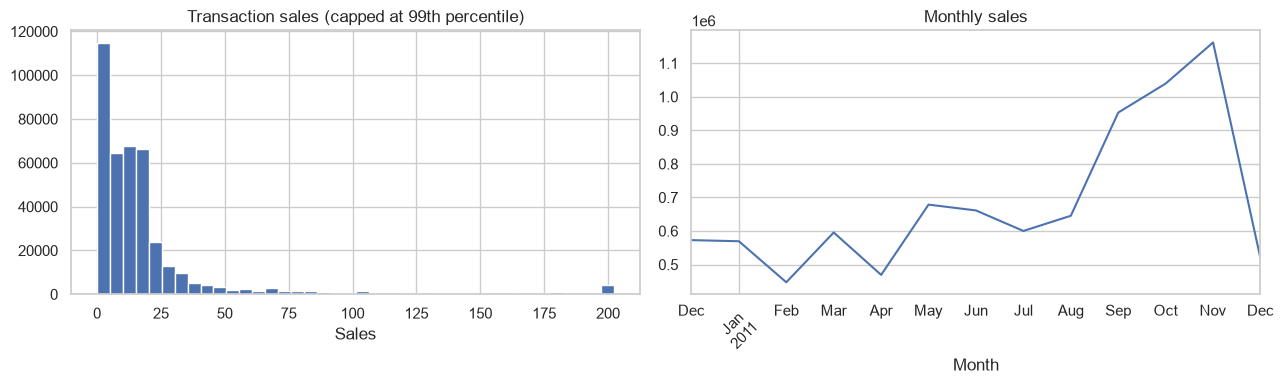

In [4]:
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Total sales in cleaned data:", round(df["Sales"].sum(), 2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["Sales"].clip(upper=df["Sales"].quantile(.99)).hist(bins=40, ax=axes[0])
axes[0].set_title("Transaction sales (capped at 99th percentile)")
axes[0].set_xlabel("Sales")
df.groupby(df["InvoiceDate"].dt.to_period("M"))["Sales"].sum().plot(ax=axes[1])
axes[1].set_title("Monthly sales"); axes[1].set_xlabel("Month")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

#### **If clipping was not used, the X-axis would stretch all the way to 10,000+. As a result, 99% of the data would be compressed into one single microscopic sliver on the left side, making the entire distribution impossible to inspect visually.**

Text(0, 0.5, 'Frequency')

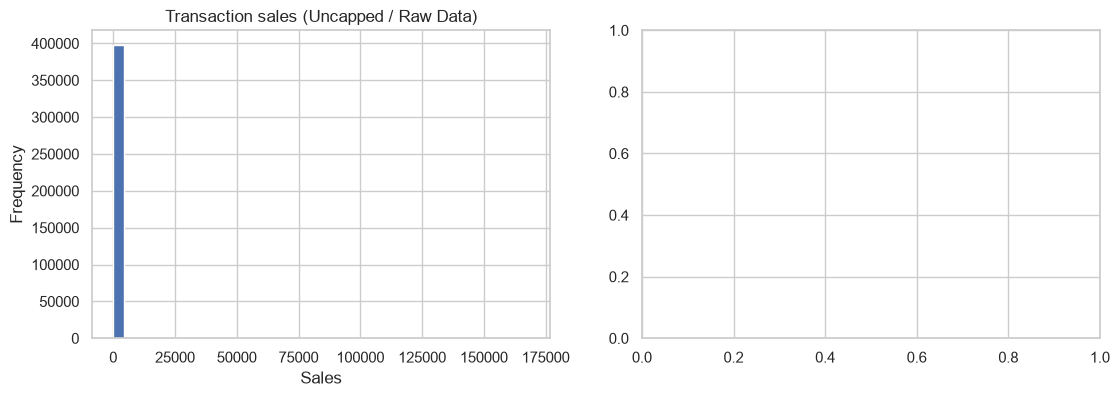

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Uncapped Histogram
df["Sales"].hist(bins=40, ax=axes[0])
axes[0].set_title("Transaction sales (Uncapped / Raw Data)")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Frequency")

## 5. Created Customer-Level RFM Features
Recency is days since the last purchase (smaller is better); Frequency is number of distinct invoices; Monetary is total sales. The reference date is one day after the last transaction in the dataset.

In [6]:
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
rfm = (df.groupby("CustomerID")
       .agg(LastPurchase=("InvoiceDate", "max"),
            Frequency=("InvoiceNo", "nunique"),
            Monetary=("Sales", "sum"))
       .reset_index())
rfm["Recency"] = (reference_date - rfm["LastPurchase"].dt.normalize()).dt.days
rfm = rfm[["CustomerID", "Recency", "Frequency", "Monetary"]]
rfm = rfm[(rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)].copy()
print("RFM shape:", rfm.shape)
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)

RFM shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059474,100.012264,1.00,18.000,51.000,142.75,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.000,2.000,5.00,209.00
Monetary,4338.0,2054.266460,8989.230441,3.75,307.415,674.485,1661.74,280206.02


## 6. Transformed and Standardised the RFM Features
Retail frequency and monetary values are usually skewed. We use `log1p` followed by standardisation so features are on comparable scales.

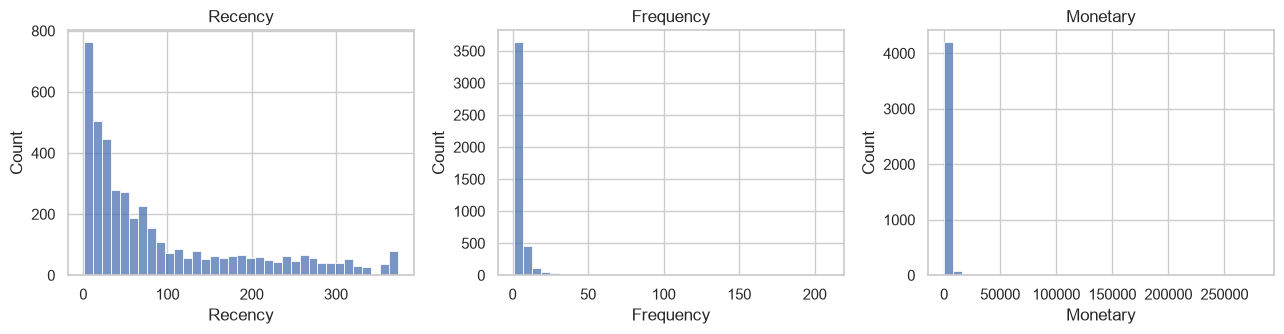

Model matrix: (4338, 3)


In [7]:
features = ["Recency", "Frequency", "Monetary"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, features):
    sns.histplot(rfm[col], bins=35, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

X_log = np.log1p(rfm[features].astype(float))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
print("Model matrix:", X_scaled.shape)

## 7. Choosed K using Elbow and Silhouette Methods
We test K = 2 through K = 8. These diagnostics support judgement rather than mechanically proving the best K. The source paper describes three segments, so K = 3 is our main paper-aligned model.

,K,Inertia,Silhouette Score
0,2,6474.146444,0.432624
1,3,4856.484636,0.337749
2,4,3924.459699,0.335547
3,5,3268.211919,0.318192
4,6,2840.151416,0.315561
5,7,2533.024427,0.310149
6,8,2325.523036,0.301952


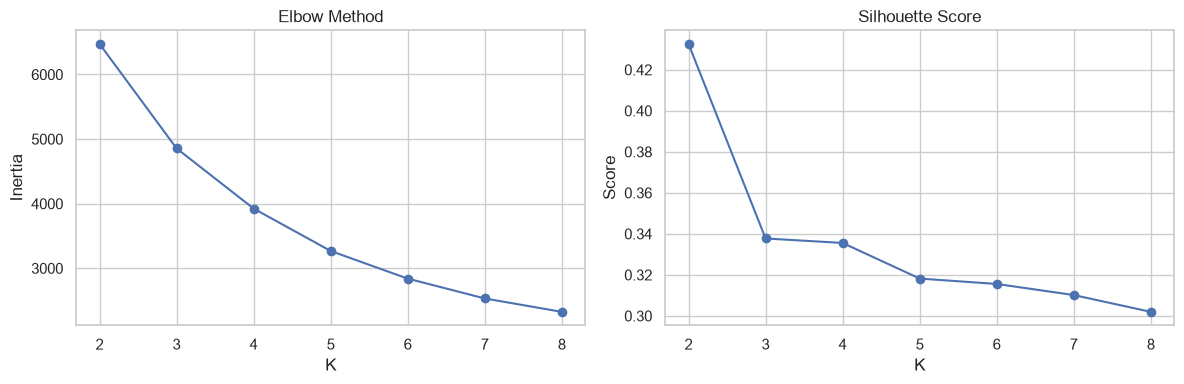

Highest silhouette among tested K: 2


In [8]:
k_values = list(range(2, 9))
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
metrics_by_k = pd.DataFrame({"K": k_values, "Inertia": inertias, "Silhouette Score": silhouettes})
display(metrics_by_k)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker="o"); axes[0].set(title="Elbow Method", xlabel="K", ylabel="Inertia")
axes[1].plot(k_values, silhouettes, marker="o"); axes[1].set(title="Silhouette Score", xlabel="K", ylabel="Score")
plt.tight_layout(); plt.show()
print("Highest silhouette among tested K:", int(metrics_by_k.loc[metrics_by_k["Silhouette Score"].idxmax(), "K"]))

## 8. Fitting K-Means with three Clusters
Cluster IDs are arbitrary. We interpret the clusters using the original RFM values rather than assuming Cluster 0 is best.

In [9]:
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=50)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)
sizes = rfm["Cluster"].value_counts().sort_index().rename("Customers")
shares = (sizes / len(rfm) * 100).rename("Customer Share (%)")
display(pd.concat([sizes, shares], axis=1))
display(rfm.groupby("Cluster")[features].agg(["mean", "median"]).round(2))

,Customers,Customer Share (%)
Cluster,,
0,757,17.450438
1,1886,43.476256
2,1695,39.073306


Recency        Frequency        Monetary         
           mean median      mean median     mean   median
Cluster                                                  
0         17.66   10.0     13.49   10.0  8001.93  3722.82
1        167.69  158.0      1.36    1.0   365.87   299.81
2         43.70   30.0      3.39    3.0  1276.65   982.38

## 9. Assigned Descriptive Segment Labels
The best profile has lower Recency and higher Frequency and Monetary values. The labels below are assigned from the observed cluster medians. “Churn-Risk” means relatively low/stale engagement in this snapshot.

In [10]:
profile = rfm.groupby("Cluster")[features].median()
# Rank Cluster Medians: Lower Recency is better; Higher Frequency/Monetary are better.
ranked = pd.DataFrame(index=profile.index)
ranked["RecencyRank"] = profile["Recency"].rank(ascending=True)
ranked["FrequencyRank"] = profile["Frequency"].rank(ascending=False)
ranked["MonetaryRank"] = profile["Monetary"].rank(ascending=False)
ranked["CompositeRank"] = ranked.mean(axis=1)
best_cluster = ranked["CompositeRank"].idxmin()
worst_cluster = ranked["CompositeRank"].idxmax()
remaining = [c for c in profile.index if c not in [best_cluster, worst_cluster]]
labels_map = {best_cluster: "Toppers / High-value", worst_cluster: "Churn-risk / Low-engagement"}
if remaining:
    labels_map[remaining[0]] = "Moderated / Mid-value"
rfm["Segment"] = rfm["Cluster"].map(labels_map)
display(profile.round(2))
display(rfm.head())
print("Cluster labels:", labels_map)

,Recency,Frequency,Monetary
Cluster,,,
0,10.0,10.0,3722.82
1,158.0,1.0,299.81
2,30.0,3.0,982.38


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,2,Moderated / Mid-value
1,12347.0,3,7,4310.00,0,Toppers / High-value
2,12348.0,76,4,1797.24,2,Moderated / Mid-value
3,12349.0,19,1,1757.55,2,Moderated / Mid-value
4,12350.0,311,1,334.40,1,Churn-risk / Low-engagement


Cluster labels: {np.int32(0): 'Toppers / High-value', np.int32(1): 'Churn-risk / Low-engagement', 2: 'Moderated / Mid-value'}


## 10. Visualizing the Segments

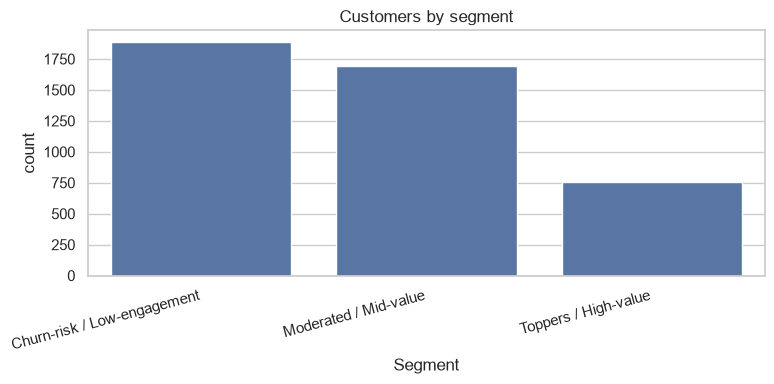

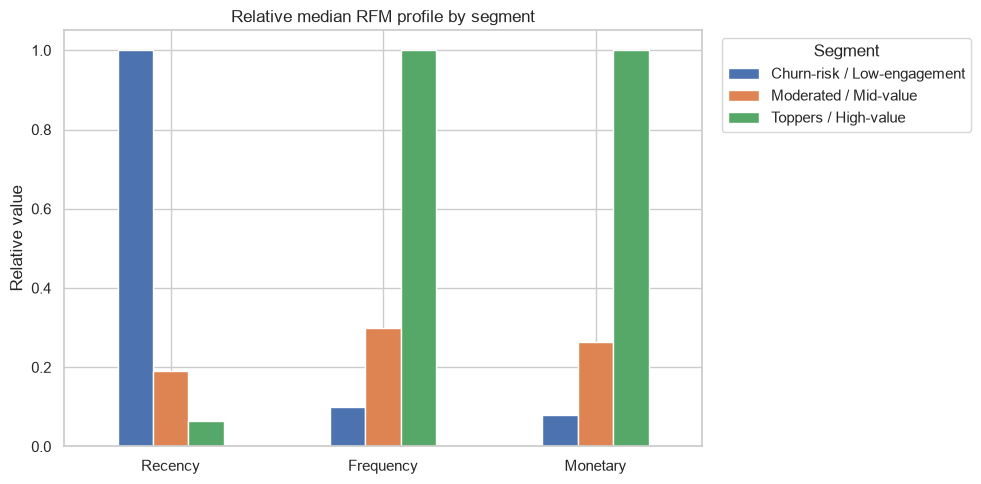

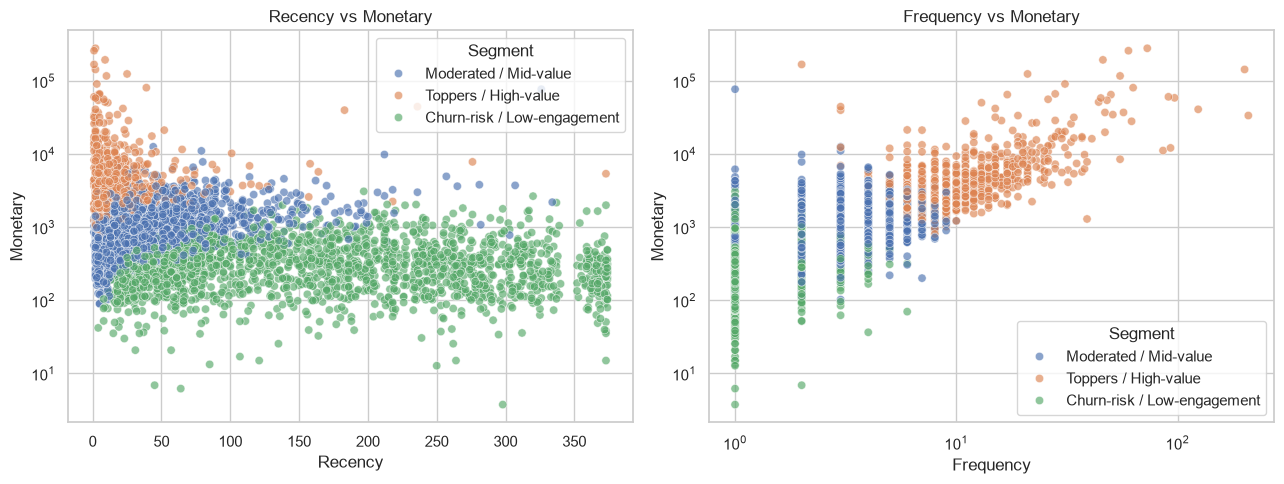

In [11]:
plt.figure(figsize=(8, 4))
order = rfm["Segment"].value_counts().index
sns.countplot(data=rfm, x="Segment", order=order)
plt.title("Customers by segment"); plt.xticks(rotation=15, ha="right")
plt.tight_layout(); plt.show()

median_profile = rfm.groupby("Segment")[features].median()
relative = median_profile.copy()
for col in features:
    mx = relative[col].max()
    relative[col] = relative[col] / mx if mx else relative[col]
relative.T.plot(kind="bar", figsize=(10, 5))
plt.title("Relative median RFM profile by segment")
plt.ylabel("Relative value"); plt.xticks(rotation=0)
plt.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Segment", alpha=.65, ax=axes[0])
axes[0].set_title("Recency vs Monetary"); axes[0].set_yscale("log")
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment", alpha=.65, ax=axes[1])
axes[1].set_title("Frequency vs Monetary"); axes[1].set_xscale("log"); axes[1].set_yscale("log")
plt.tight_layout(); plt.show()

## 11. PCA Visualization
PCA reduces the scaled three-feature data to two dimensions for plotting only.

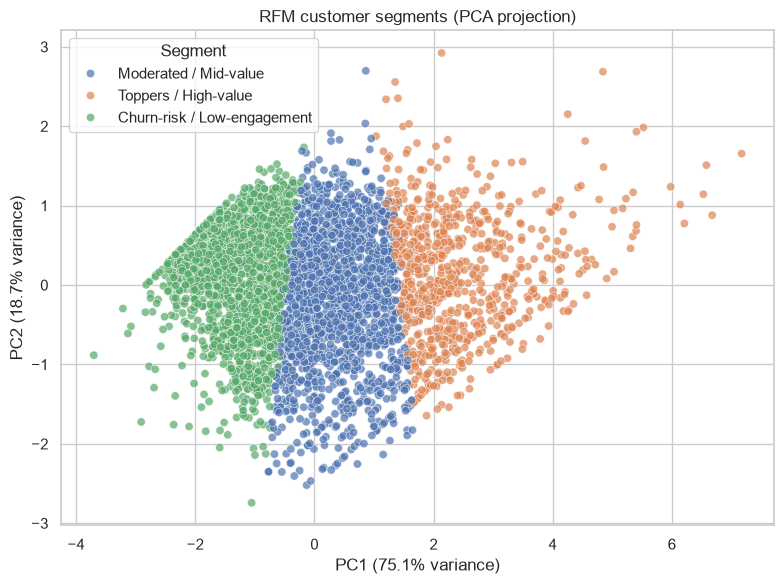

Variance explained by first two PCs: 93.86 %


In [12]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "Segment": rfm["Segment"].to_numpy()})
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Segment", alpha=.7)
plt.title("RFM customer segments (PCA projection)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout(); plt.show()
print("Variance explained by first two PCs:", round(pca.explained_variance_ratio_[:2].sum()*100, 2), "%")

## 12. Evaluating and Checking Stability
Silhouette score summarises cluster separation. The simple seed comparison below checks how similar pairwise cluster membership is across initialisations on a sample; it is descriptive, not a formal statistical test.

In [13]:
sil3 = silhouette_score(X_scaled, rfm["Cluster"])
print(f"K=3 silhouette score: {sil3:.4f}")
rng = np.random.default_rng(RANDOM_STATE)
n_sample = min(1200, len(rfm))
idx = rng.choice(len(rfm), size=n_sample, replace=False)
Xs = X_scaled[idx]
runs = []
for seed in [11, 22, 33, 44, 55]:
    runs.append(KMeans(n_clusters=3, random_state=seed, n_init=20).fit_predict(Xs))
def co_membership(labels):
    labels = np.asarray(labels)
    return labels[:, None] == labels[None, :]
base = co_membership(runs[0])
agreements = [(base == co_membership(lab)).mean() for lab in runs[1:]]
print("Mean co-membership agreement vs first seed:", round(float(np.mean(agreements)), 4))

K=3 silhouette score: 0.3377
Mean co-membership agreement vs first seed: 0.9997


## 13. Created Report-Ready Segment Summary

In [14]:
segment_report = (rfm.groupby("Segment")
    .agg(Customers=("CustomerID", "nunique"),
         Median_Recency_Days=("Recency", "median"),
         Median_Frequency_Invoices=("Frequency", "median"),
         Median_Monetary=("Monetary", "median"),
         Mean_Recency_Days=("Recency", "mean"),
         Mean_Frequency_Invoices=("Frequency", "mean"),
         Mean_Monetary=("Monetary", "mean"))
    .reset_index())
segment_report["Customer_Share_Percent"] = segment_report["Customers"] / len(rfm) * 100
display(segment_report.round(2))

,Segment,Customers,Median_Recency_Days,Median_Frequency_Invoices,Median_Monetary,Mean_Recency_Days,Mean_Frequency_Invoices,Mean_Monetary,Customer_Share_Percent
0,Churn-risk / Low-engagement,1886,158.0,1.0,299.81,167.69,1.36,365.87,43.48
1,Moderated / Mid-value,1695,30.0,3.0,982.38,43.70,3.39,1276.65,39.07
2,Toppers / High-value,757,10.0,10.0,3722.82,17.66,13.49,8001.93,17.45


## 14. Exporting the Results

In [15]:
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
rfm.to_csv(OUT / "customer_rfm_segments.csv", index=False)
segment_report.to_csv(OUT / "customer_segment_summary.csv", index=False)
metrics_by_k.to_csv(OUT / "kmeans_cluster_selection_metrics.csv", index=False)
print("Saved files to:", OUT.resolve())
print("- customer_rfm_segments.csv")
print("- customer_segment_summary.csv")
print("- kmeans_cluster_selection_metrics.csv")

Saved files to: outputs
- customer_rfm_segments.csv
- customer_segment_summary.csv
- kmeans_cluster_selection_metrics.csv


## 15. Drafting Findings for the Report

In [16]:
best = segment_report.sort_values("Median_Monetary", ascending=False).iloc[0]
least = segment_report.sort_values("Median_Monetary", ascending=True).iloc[0]
print("DRAFT RESULTS NOTES")
print(f"Customers analysed: {len(rfm):,}")
print(f"Transactions retained after cleaning: {len(df):,}")
print(f"Number of clusters: {K_FINAL}")
print(f"Silhouette score (K=3): {sil3:.4f}")
print(f"Highest median-spending segment: {best['Segment']} ({best['Customer_Share_Percent']:.1f}% of customers)")
print(f"  Median Recency: {best['Median_Recency_Days']:.1f} days")
print(f"  Median Frequency: {best['Median_Frequency_Invoices']:.1f} invoices")
print(f"  Median Monetary: {best['Median_Monetary']:.2f}")
print(f"Lowest median-spending segment: {least['Segment']} ({least['Customer_Share_Percent']:.1f}% of customers)")
print(f"  Median Recency: {least['Median_Recency_Days']:.1f} days")
print(f"  Median Frequency: {least['Median_Frequency_Invoices']:.1f} invoices")
print(f"  Median Monetary: {least['Median_Monetary']:.2f}")
print("These are descriptive results from UCI Online Retail, not the source article's results.")

DRAFT RESULTS NOTES
Customers analysed: 4,338
Transactions retained after cleaning: 397,884
Number of clusters: 3
Silhouette score (K=3): 0.3377
Highest median-spending segment: Toppers / High-value (17.5% of customers)
  Median Recency: 10.0 days
  Median Frequency: 10.0 invoices
  Median Monetary: 3722.82
Lowest median-spending segment: Churn-risk / Low-engagement (43.5% of customers)
  Median Recency: 158.0 days
  Median Frequency: 1.0 invoices
  Median Monetary: 299.81
These are descriptive results from UCI Online Retail, not the source article's results.


## 16. E-Commerce Sales Prediction
Predicts **daily sales for a historical holdout period** using a Random Forest regressor. Missing calendar dates are filled with zero sales (an assumption). Features use only sales observed *before* each target date, avoiding look-ahead leakage. A chronological 80/20 split is used. The test represents **one-day-ahead prediction with previous actual sales available**; it is not a multi-day recursive forecast.

Train: 288 days | Test: 72 days
Test interval: 2011-09-29 to 2011-12-09
Random Forest MAE: 11260.04
Random Forest RMSE: 21908.12
Random Forest R2: 0.3138
Seasonal naive MAE: 13155.37
Seasonal naive RMSE: 22451.47
WAPE (%): 28.91


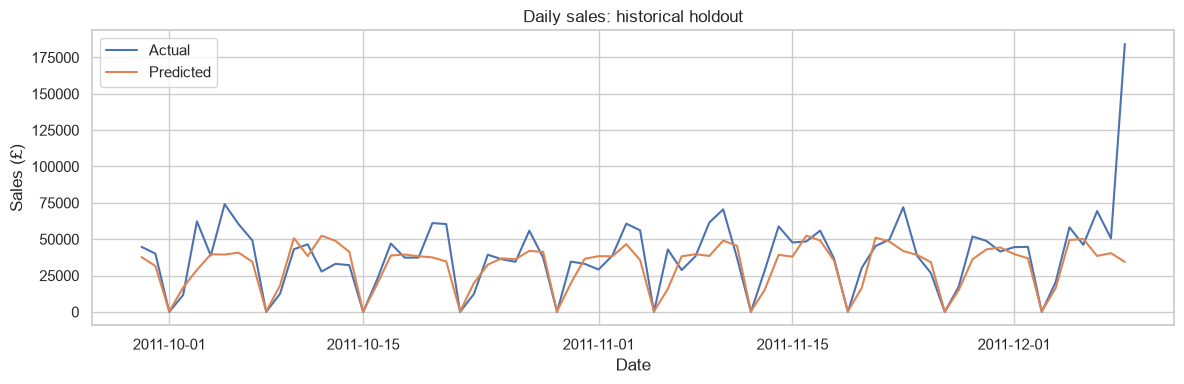

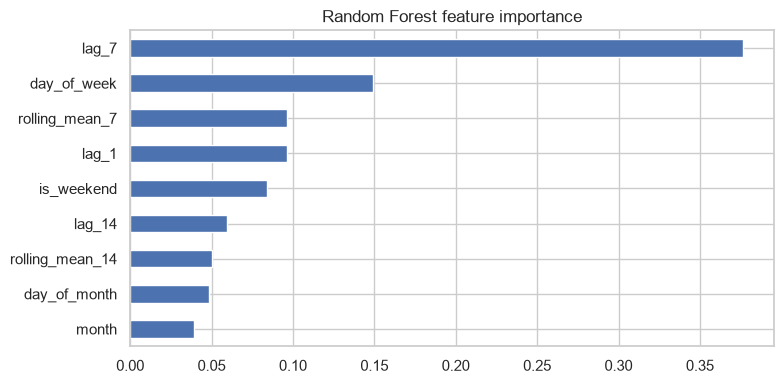

Saved outputs/daily_sales_test_predictions.csv


In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Reuse cleaned df and Sales computed above.
daily_sales = df.groupby(df['InvoiceDate'].dt.normalize())['Sales'].sum().sort_index().asfreq('D', fill_value=0).to_frame('Sales')
for lag in (1, 7, 14):
    daily_sales[f'lag_{lag}'] = daily_sales['Sales'].shift(lag)
daily_sales['rolling_mean_7'] = daily_sales['Sales'].shift(1).rolling(7).mean()
daily_sales['rolling_mean_14'] = daily_sales['Sales'].shift(1).rolling(14).mean()
daily_sales['day_of_week'] = daily_sales.index.dayofweek
daily_sales['month'] = daily_sales.index.month
daily_sales['day_of_month'] = daily_sales.index.day
daily_sales['is_weekend'] = (daily_sales.index.dayofweek >= 5).astype(int)
forecast_data = daily_sales.dropna()
forecast_features = ['lag_1','lag_7','lag_14','rolling_mean_7','rolling_mean_14','day_of_week','month','day_of_month','is_weekend']
split = int(len(forecast_data) * .8)
train, test = forecast_data.iloc[:split], forecast_data.iloc[split:]
regressor = RandomForestRegressor(n_estimators=180, max_depth=9, min_samples_leaf=3, random_state=42, n_jobs=-1)
regressor.fit(train[forecast_features], train['Sales'])
y_pred = regressor.predict(test[forecast_features])
naive_pred = test['lag_7'].to_numpy()
print('Train:',len(train),'days | Test:',len(test),'days')
print('Test interval:',test.index.min().date(),'to',test.index.max().date())
print('Random Forest MAE:',round(mean_absolute_error(test['Sales'],y_pred),2))
print('Random Forest RMSE:',round(np.sqrt(mean_squared_error(test['Sales'],y_pred)),2))
print('Random Forest R2:',round(r2_score(test['Sales'],y_pred),4))
print('Seasonal naive MAE:',round(mean_absolute_error(test['Sales'],naive_pred),2))
print('Seasonal naive RMSE:',round(np.sqrt(mean_squared_error(test['Sales'],naive_pred)),2))
print('WAPE (%):',round(np.abs(test['Sales'].to_numpy()-y_pred).sum()/test['Sales'].sum()*100,2))
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(test.index,test['Sales'],label='Actual',linewidth=1.5)
ax.plot(test.index,y_pred,label='Predicted',linewidth=1.5)
ax.set(title='Daily sales: historical holdout',xlabel='Date',ylabel='Sales (£)');ax.legend();plt.tight_layout();plt.show()
feature_imp = pd.Series(regressor.feature_importances_,index=forecast_features).sort_values()
feature_imp.plot.barh(figsize=(8,4),title='Random Forest feature importance');plt.tight_layout();plt.show()
forecast_export = pd.DataFrame({'Date':test.index,'Actual_Sales':test['Sales'].values,'Predicted_Sales':y_pred,'Seasonal_Naive_Lag7':naive_pred})
OUT = Path('outputs');OUT.mkdir(exist_ok=True)
forecast_export.to_csv(OUT/'daily_sales_test_predictions.csv',index=False)
print('Saved outputs/daily_sales_test_predictions.csv')

## 17. Business Interpretation and Limitations
- **Sales Analysis:** Monthly sales shows variation in revenue over time and across markets.
- **Prediction:** Evaluated Random Forest against the 7-day seasonal-naive baseline; a model is useful only when it improves an appropriate baseline.
- **Segmentation:** RFM–K-Means results are: 757 high-value, 1,695 mid-value, 1,886 low-engagement customers.
- **Limitations:** Only about one year of data, zero-sales imputation for dates without transactions, non-stationary demand, and no promotion/holiday variables. The predictions are one-step historical holdout estimates using prior actual sales, not validated long-horizon forecasts. K=2 has the best silhouette score but K=3 is retained for interpretability.

**References:** Chen (2015), UCI Online Retail dataset; Mehta & Sehgal (2024), retail micro-segmentation; Rousseeuw (1987), silhouette coefficient.

## References

Mehta, D., & Sehgal, S. (2024). A study on micro-segmentation of retail customers using K-means clustering. *Journal of Business Thought, 15*, 75–87. https://doi.org/10.18311/jbt/2024/44468

Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33